# Context embeddings: E3 recruiter, target and cell line

Dense, PCA-compressed representations of the three *biological context* entities of a PROTAC measurement, cached next to the other TACK
embeddings (the same recipe as `assay_embeddings.ipynb`, applied to the other context columns):

| block | key | encoder | pooling |
|---|---|---|---|
| **recruiter** (E3 ligase) | amino-acid sequence | `ProteinEmbedding` (ESM-2 150M, 640-d) | **sum** |
| **target** (POI) | amino-acid sequence | `ProteinEmbedding` (ESM-2 150M, 640-d) | **sum** |
| **cell line** | Cellosaurus accession | `CellEmbedding` (sentence transformer on the Cellosaurus description, 768-d) | **mean** |

The three blocks are processed **independently**: each gets its own vocabulary, its own PCA, and its own cache files.
The vocabularies are collected from every CSV in `data/yaochen/`, **including `PROTAC-test.csv`** (its sequences and cell lines also occur in the other CSVs, so including it adds nothing new; section 1 asserts this).

| section | content |
|---|---|
| 1 | Vocabularies from all CSVs |
| 2 | Embeddings with the repo's own `ProteinEmbedding` / `CellEmbedding` classes (long sequences are windowed) |
| 3 | PCA compression: components needed for 90 % of the variance, per block |
| 4 | Cache files (`TACKAI_CACHE`): full embeddings, PCA embeddings, fitted PCA, metadata |
| 5 | Similarity of the entities |
| 6 | Summary and a **standalone cell** that loads the cache with nothing but its own imports |

Every section ends with a test cell (plain `assert`s, printing `OK`); the notebook runs top to bottom with no manual steps.

## Setup

In [1]:
import os, sys, json, re, math, warnings, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform, pdist
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from tqdm.auto import tqdm
from dotenv import load_dotenv, find_dotenv

from tackai.data.utils import get_cache_dir
from tackai.data.embeddings.utils import EmbeddingMixin
from tackai.data.embeddings.protein_embeddings import ProteinEmbedding, sanitize_sequence
from tackai.data.embeddings.cell_embeddings import CellEmbedding

# macOS: torch and xgboost each bundle their own libomp, and multi-threaded use of both in one process segfaults (the other notebooks set
# OMP_NUM_THREADS=1 for that reason). This notebook never imports xgboost, so torch may use all cores; the assert keeps that premise honest.
assert "xgboost" not in sys.modules, "xgboost is loaded: set OMP_NUM_THREADS=1 before importing torch (see the other notebooks)"

warnings.filterwarnings("ignore", category=FutureWarning)
load_dotenv(find_dotenv())  # picks up TACKAI_CACHE from .env when present; otherwise ~/.cache/tackai

# ----- configuration -------------------------------------------------------------------------------------------------
BLOCKS = ("recruiter", "target", "cell")
ESM_MODEL = "facebook/esm2_t30_150M_UR50D"      # 640-d; the checkpoint fusion_comparison.ipynb uses for the POI block
ESM_TAG = ESM_MODEL.replace("/", "-")           # how ProteinEmbedding writes the model into its default file names
PROTEIN_POOLING = "sum"                         # pooling over residues (ProteinEmbedding) and then over windows (this notebook)
WINDOW = 1022                                   # residues per ESM-2 window (1024-token context minus BOS/EOS)
CELL_MODEL = "sentence-transformers/all-mpnet-base-v1"
CELL_POOLING = "mean"                           # pooling over the tokens of a cell-line description
NOT_FOUND = "Unknown cell line."                # CellEmbedding's description for a missing / unknown cell line
VARIANCE_TARGET = 0.90                          # PCA keeps the fewest components that explain this share of the variance
SIMILARITY_TARGET = 0.95                        # ... and at least this Spearman correlation of the centred pairwise cosines (None: variance only)
TEST_FILE = "PROTAC-test.csv"                   # included on purpose (see section 1)
RECOMPUTE = False                               # True: ignore cached full embeddings and encode everything again

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "yaochen").is_dir())
DATA_DIR = ROOT / "data" / "yaochen"
OUT_DIR = ROOT / "notebooks" / "context_embedding_results"
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path(get_cache_dir())
print(f"data: {DATA_DIR}\nfigures: {OUT_DIR}\ncache: {CACHE_DIR}\ntorch threads: {torch.get_num_threads()}")

/Users/ribes/phd/TACK/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data: /Users/ribes/phd/TACK/data/yaochen
figures: /Users/ribes/phd/TACK/notebooks/context_embedding_results
cache: /Users/ribes/.cache/tackai
torch threads: 5


## 1. Vocabularies

One vocabulary per block, collected from **every CSV** in `data/yaochen/` (the files overlap heavily, so the vocabularies are far smaller than the row counts):

* **recruiter**: distinct `Recruiter_Sequence` strings (the E3 ligase, e.g. CRBN, VHL, DCAF1);
* **target**: distinct `Degradation_Target_Sequence` strings (the protein of interest, wild type and mutants);
* **cell**: distinct Cellosaurus accessions (`Cell_Line_ID` in `TACKv2.csv`, `Cell_Line_STD_Accession` in the others) plus the not-found description for rows without an accession.
  The datamodule looks cells up by accession (`cell_line_col="Cell_Line_ID"`), and so did the existing `cell_embeddings_model=sentence-transformer_pooling=sum.npz` cache, so the new keys are interchangeable with it.

`PROTAC-test.csv` is **not excluded**: every recruiter, target and accession in it also occurs in the other CSVs, so it contributes no entity that the development data lack (checked below and asserted in the test cell).
Sequences are stripped of whitespace only; the cache is keyed by the raw sequence, exactly as `ProteinEmbedding` keys its embeddings.

In [2]:
KEY_COLUMNS = {"recruiter": ("Recruiter_Sequence",), "target": ("Degradation_Target_Sequence",),
               "cell": ("Cell_Line_ID", "Cell_Line_STD_Accession")}      # first column present in a file wins
LABEL_COLUMNS = {"recruiter": "Recruiter_Gene", "target": "Degradation_Target_Gene", "cell": "Cell_Line"}   # only used to name entities in plots

def _clean(series):
    """Strip whitespace; empty strings and the text 'nan' become missing."""
    s = series.astype("string").str.strip()
    return s.mask(s.isna() | (s == "") | (s.str.lower() == "nan"))

def load_context_rows(data_dir):
    """Read the recruiter, target and cell-line columns of every CSV in ``data_dir`` into one long frame.

    Args:
        data_dir: Directory with the CSV files.

    Returns:
        DataFrame with one row per CSV row and the columns ``file``, ``recruiter``, ``target``, ``cell`` (the keys; missing values are
        ``pd.NA``) and ``recruiter_label``, ``target_label``, ``cell_label`` (human-readable names used for plots).
    """
    parts = []
    for path in sorted(data_dir.glob("*.csv")):
        header = pd.read_csv(path, nrows=0).columns
        key_cols = {b: next(c for c in KEY_COLUMNS[b] if c in header) for b in BLOCKS}
        df = pd.read_csv(path, usecols=sorted(set(key_cols.values()) | set(LABEL_COLUMNS.values())), dtype="string", low_memory=False)
        part = pd.DataFrame({"file": path.name}, index=df.index)
        for b in BLOCKS:
            part[b] = _clean(df[key_cols[b]])
            part[f"{b}_label"] = _clean(df[LABEL_COLUMNS[b]])
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

ROWS = load_context_rows(DATA_DIR)
N_MISSING_CELL = int(ROWS["cell"].isna().sum())
ROWS["cell"] = ROWS["cell"].fillna(NOT_FOUND)   # a row without accession is looked up as the not-found description (what CellEmbedding does for None / "")

COUNTS = {b: ROWS[b].value_counts() for b in BLOCKS}                      # rows per entity (the files overlap: not unique measurements)
VOCAB = {b: sorted(COUNTS[b].index, key=lambda k: (-COUNTS[b][k], k)) for b in BLOCKS}
if NOT_FOUND in VOCAB["cell"]:
    VOCAB["cell"] = [k for k in VOCAB["cell"] if k != NOT_FOUND] + [NOT_FOUND]    # keep the not-found key last, like `unknown` in the assay tables

def entity_labels(block):
    """Readable name per vocabulary key: gene (upper case) and length for sequences, cell-line name and accession for cells."""
    sub = ROWS.dropna(subset=[block, f"{block}_label"])
    top = sub.groupby(block)[f"{block}_label"].agg(lambda s: s.value_counts().index[0])
    if block == "cell":
        return {k: NOT_FOUND if k == NOT_FOUND else f"{top.get(k, '?')} ({k})" for k in VOCAB[block]}
    labels, seen = {}, {}
    for k in VOCAB[block]:
        base = f"{str(top.get(k, '?')).upper()}, {len(k)} aa"
        seen[base] = seen.get(base, 0) + 1
        labels[k] = base if seen[base] == 1 else f"{base} (#{seen[base]})"          # same gene and length (e.g. a point mutant): keep labels unique
    return labels

LABELS = {b: entity_labels(b) for b in BLOCKS}
IN_TEST = {b: set(ROWS.loc[ROWS["file"] == TEST_FILE, b].dropna()) for b in BLOCKS}
IN_DEV = {b: set(ROWS.loc[ROWS["file"] != TEST_FILE, b].dropna()) for b in BLOCKS}
TEST_ONLY = {b: IN_TEST[b] - IN_DEV[b] for b in BLOCKS}

summary = pd.DataFrame({b: {"vocabulary": len(VOCAB[b]), f"in {TEST_FILE}": len(IN_TEST[b]), "in the other CSVs": len(IN_DEV[b]),
                            f"only in {TEST_FILE}": len(TEST_ONLY[b]), "rows": int(COUNTS[b].sum())} for b in BLOCKS}).T
print(f"{ROWS['file'].nunique()} CSV files, {len(ROWS):,} rows ({N_MISSING_CELL:,} without a cell-line accession -> '{NOT_FOUND}')")
print(summary.to_string())
print("\nmost frequent entities (rows pooled over the overlapping files):")
for b in BLOCKS:
    print(f"  {b}: " + "; ".join(f"{LABELS[b][k]} x{COUNTS[b][k]:,}" for k in VOCAB[b][:4]))
seq_len = {b: pd.Series([len(k) for k in VOCAB[b]]) for b in ("recruiter", "target")}
for b, s in seq_len.items():
    print(f"{b} sequence length: median {int(s.median())}, max {int(s.max())}; {(s > WINDOW).sum()} of {len(s)} longer than one {WINDOW}-residue window")

7 CSV files, 13,795 rows (716 without a cell-line accession -> 'Unknown cell line.')
           vocabulary  in PROTAC-test.csv  in the other CSVs  only in PROTAC-test.csv   rows
recruiter          17                   4                 17                        0  13594
target            204                  23                204                        0  13283
cell              201                  28                201                        0  13795

most frequent entities (rows pooled over the overlapping files):
  recruiter: CRBN, 442 aa x7,973; VHL, 213 aa x4,819; CRBN, 445 aa x365; BIRC2, 618 aa x174
  target: AR, 920 aa x1,282; BTK, 659 aa x1,107; BRD4, 1362 aa x803; SMARCA2, 1590 aa x769
  cell: MCF-7 (CVCL_0031) x673; LNCaP (CVCL_0395) x652; HCT116 (CVCL_0291) x619; MDA-MB-231 (CVCL_0062) x531
recruiter sequence length: median 497, max 1749; 2 of 17 longer than one 1022-residue window
target sequence length: median 603, max 7096; 40 of 204 longer than one 1022-residue window


In [3]:
# ----- test: vocabularies ------------------------------------------------------------------------------------------------
import csv

# independent re-read with the csv module: the union of the stripped, non-empty values per file must equal the vocabulary
def csv_values(path, columns):
    with open(path, newline="", encoding="utf-8") as fh:
        reader = csv.DictReader(fh)
        col = next(c for c in columns if c in reader.fieldnames)
        return [row[col].strip() for row in reader if row[col] and row[col].strip() and row[col].strip().lower() != "nan"]

paths = sorted(DATA_DIR.glob("*.csv"))
assert ROWS["file"].nunique() == len(paths) and TEST_FILE in set(ROWS["file"]), "every CSV, the test file included, must be read"
for b in BLOCKS:
    pooled = [v for p in paths for v in csv_values(p, KEY_COLUMNS[b])]
    want = set(pooled) | ({NOT_FOUND} if b == "cell" and N_MISSING_CELL else set())
    assert set(VOCAB[b]) == want and len(VOCAB[b]) == len(set(VOCAB[b])), b
    if b != "cell":
        assert int(COUNTS[b].sum()) == len(pooled), b                        # row counts agree with the independent count
    assert all(k == k.strip() and k and k.lower() != "nan" for k in VOCAB[b]), b

# keys: sequences are letters only; cell keys are Cellosaurus accessions (plus the not-found description)
for b in ("recruiter", "target"):
    assert all(re.fullmatch(r"[A-Za-z]+", k) for k in VOCAB[b]), f"{b}: a key is not an amino-acid string"
assert all(re.fullmatch(r"CVCL_[A-Z0-9]+", k) or k == NOT_FOUND for k in VOCAB["cell"]), "unexpected cell-line key"
assert VOCAB["cell"][-1] == NOT_FOUND and N_MISSING_CELL > 0

# the test file is included, and it adds nothing the other CSVs lack (so including it cannot leak a held-out entity into the vocabulary)
assert all(len(IN_TEST[b]) > 0 for b in BLOCKS)
assert all(not TEST_ONLY[b] for b in BLOCKS), {b: sorted(TEST_ONLY[b])[:3] for b in BLOCKS if TEST_ONLY[b]}
assert set(VOCAB["recruiter"]) >= IN_TEST["recruiter"] and set(VOCAB["target"]) >= IN_TEST["target"]

# ordering and labels
for b in BLOCKS:
    counts = [COUNTS[b].get(k, 0) for k in VOCAB[b] if k != NOT_FOUND]
    assert counts == sorted(counts, reverse=True), f"{b}: vocabulary not ordered by row count"
    assert list(LABELS[b]) == VOCAB[b] and all(LABELS[b].values())
assert len(set(LABELS["recruiter"].values())) == len(VOCAB["recruiter"]), "two recruiters share a plot label"
print("vocabularies: OK (" + "; ".join(f"{b} {len(VOCAB[b])}" for b in BLOCKS) + f" entities from {len(paths)} CSVs, {TEST_FILE} included and adding none)")

vocabularies: OK (recruiter 17; target 204; cell 201 entities from 7 CSVs, PROTAC-test.csv included and adding none)


## 2. Embeddings with the repo's classes

### 2.1 Recruiter and target: `ProteinEmbedding`, sum pooling, windows for long sequences

`ProteinEmbedding(embeddings_type="esm", pooling="sum")` tokenises a sequence, runs ESM-2 and **sums the last hidden states over the token axis** (one 640-d vector).
Two properties of that class matter here, and the code below handles both:

* **Context limit.** ESM-2 reads at most 1024 tokens, and the class truncates anything longer silently. Targets reach 7,096 residues, so a sequence longer than `WINDOW = 1022` residues is split
  into `ceil(L / 1022)` **balanced windows** (sizes differ by at most one residue, so there is no 1-residue tail), each window is embedded by the class, and the window vectors are **summed**, i.e. sum pooling again.
  A sequence that fits in one window is embedded exactly as the class would do it.
* **Padding.** The class sums over *all* positions of a padded batch, so the vector of a sequence would depend on the other sequences in its batch. The encoder therefore runs with
  `batch_size=1`; no padding ever enters a sum. (The test cell shows that a padded batch really does change the vectors.)

The class sums the BOS and EOS token states too (it makes no attempt to remove them), so a windowed sequence contains two special-token states per window. That is a small constant per window,
not a length-dependent signal, and it is left as the class defines it. Sum pooling makes the vector norm grow with sequence length: this is what was asked for, and PCA centring removes the shared component.

In [4]:
def stem_of(block):
    """File-name stem of a block's cache files; follows the naming of the classes' default file names."""
    if block == "cell":
        return f"cell_embeddings_model=sentence-transformer_pooling={CELL_POOLING}"
    return f"protein_embeddings_esm_model={ESM_TAG}_pooling={PROTEIN_POOLING}_window={WINDOW}_block={block}"

FULL_FILES = {b: f"{stem_of(b)}.npz" for b in BLOCKS}

def window_sequence(seq, size=WINDOW):
    """Split a sequence into ``ceil(len / size)`` balanced windows of at most ``size`` residues (after the class's own sanitising).

    Args:
        seq: Amino-acid sequence.
        size: Maximum residues per window.

    Returns:
        List of strings whose concatenation is ``sanitize_sequence(seq)``; lengths differ by at most one.
    """
    seq = sanitize_sequence(seq)
    if not seq:
        raise ValueError("cannot embed an empty sequence")
    bounds = np.linspace(0, len(seq), math.ceil(len(seq) / size) + 1).round().astype(int)
    return [seq[a:b] for a, b in zip(bounds[:-1], bounds[1:])]

# one ProteinEmbedding does all the encoding: batch_size=1 (no padding), sum pooling over residues; the model is loaded once
window_encoder = ProteinEmbedding(embeddings_type="esm", pretrained_model=ESM_MODEL, model=ESM_MODEL, tokenizer=ESM_MODEL,
                                  batch_size=1, pooling=PROTEIN_POOLING)

def embed_sequences(seqs, encoder=None, chunk=16):
    """Embed sequences with ``ProteinEmbedding``: windows of at most ``WINDOW`` residues, summed over windows.

    Args:
        seqs: Iterable of amino-acid sequences.
        encoder: A ``ProteinEmbedding`` (default: ``window_encoder``); its cache of window vectors is reused.
        chunk: Windows encoded per progress step.

    Returns:
        Dict ``sequence -> float32 vector`` (the sequence as passed in is the key, like ``ProteinEmbedding``).
    """
    encoder = window_encoder if encoder is None else encoder
    seqs = list(dict.fromkeys(seqs))
    windows = {s: window_sequence(s) for s in seqs}
    todo = [w for w in dict.fromkeys(w for ws in windows.values() for w in ws) if w not in encoder]
    for i in tqdm(range(0, len(todo), chunk), desc="ESM windows", unit=f"x{chunk}", leave=False):
        encoder.transform(todo[i:i + chunk])
    return {s: np.sum([encoder[w] for w in windows[s]], axis=0, dtype=np.float64).astype(np.float32) for s in seqs}

def protein_table(block):
    """Embeddings of a block's vocabulary: loaded from the cache when present, only the missing sequences are encoded."""
    store = ProteinEmbedding(embeddings_type="esm", pretrained_model=ESM_MODEL, pooling=PROTEIN_POOLING, filename=FULL_FILES[block],
                             cache_dir=CACHE_DIR, load_from_cache=not RECOMPUTE)
    missing = [k for k in VOCAB[block] if k not in store]
    store.embeddings.update(embed_sequences(missing))
    print(f"{block}: {len(VOCAB[block]) - len(missing)} sequences from the cache, {len(missing)} encoded")
    return {k: np.asarray(store[k], dtype=np.float32) for k in VOCAB[block]}

TABLES = {b: protein_table(b) for b in ("recruiter", "target")}

Loading weights:   0%|          | 0/486 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 486/486 [00:00<00:00, 7409.78it/s]


[transformers] EsmModel LOAD REPORT from: facebook/esm2_t30_150M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ESM windows:   0%|          | 0/2 [00:00<?, ?x16/s]

ESM windows:  50%|█████     | 1/2 [00:08<00:08,  8.24s/x16]

ESM windows: 100%|██████████| 2/2 [00:09<00:00,  3.95s/x16]

... (15 outputs left out)

ESM windows:  88%|████████▊ | 14/16 [01:54<00:16,  8.02s/x16]

ESM windows:  94%|█████████▍| 15/16 [02:00<00:07,  7.46s/x16]

ESM windows: 100%|██████████| 16/16 [02:01<00:00,  5.61s/x16]

target: 0 sequences from the cache, 204 encoded


### 2.2 Cell line: `CellEmbedding`, mean pooling

`CellEmbedding(embeddings_type="sentence_transformer", pooling="mean")` looks up the **Cellosaurus description** of an accession (organism, tissue, disease, ...), runs the sentence transformer
(`all-mpnet-base-v1`, the encoder of the existing cell-line cache) and **averages the token embeddings** into one 768-d vector. The existing cache uses `pooling="sum"`; the new file carries `pooling=mean` in its name,
so the two never overwrite each other. For one accession the two differ by exactly the number of description tokens (checked in the test cell against the old file).
Rows without an accession map to the not-found description, `"Unknown cell line."`, which has its own vector.

In [5]:
cell_encoder = CellEmbedding(embeddings_type="sentence_transformer", pretrained_model=CELL_MODEL, pooling=CELL_POOLING,
                             not_found_description=NOT_FOUND, filename=FULL_FILES["cell"], cache_dir=CACHE_DIR, load_from_cache=not RECOMPUTE)
missing = [k for k in VOCAB["cell"] if k not in cell_encoder]
if missing:
    cell_encoder.transform(missing)
print(f"cell: {len(VOCAB['cell']) - len(missing)} accessions from the cache, {len(missing)} encoded")
TABLES["cell"] = {k: np.asarray(cell_encoder[k], dtype=np.float32) for k in VOCAB["cell"]}

EMB_DIM = {b: next(iter(TABLES[b].values())).shape[0] for b in BLOCKS}
print({b: f"{len(TABLES[b])} x {EMB_DIM[b]}" for b in BLOCKS})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7068.53it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17626.10it/s]

cell: 0 accessions from the cache, 201 encoded
{'recruiter': '17 x 640', 'target': '204 x 640', 'cell': '201 x 768'}


In [6]:
# ----- test: embeddings --------------------------------------------------------------------------------------------------
from transformers import AutoModel, AutoTokenizer
from sentence_transformers import SentenceTransformer

# window_sequence: lossless, bounded, balanced
long_seq = max(VOCAB["target"], key=len)
for seq in [VOCAB["recruiter"][0], long_seq, "A" * 1022, "A" * 1023, "A" * 2044, "A" * 2045]:
    ws = window_sequence(seq)
    assert "".join(ws) == sanitize_sequence(seq)
    assert len(ws) == math.ceil(len(seq) / WINDOW) and max(map(len, ws)) <= WINDOW and max(map(len, ws)) - min(map(len, ws)) <= 1, len(seq)
assert window_sequence("ACD") == ["ACD"] and window_sequence("AUOBZJ") == ["ACKDEL"]    # sanitised exactly as ProteinEmbedding does
try:
    window_sequence("")
    raise AssertionError("an empty sequence was accepted")
except ValueError:
    pass

# the classes are configured as requested
assert window_encoder.pooling == "sum" and window_encoder.batch_size == 1 and window_encoder.embeddings_type == "esm"
assert cell_encoder.pooling == "mean" and cell_encoder.embeddings_type == "sentence_transformer"

# independent reference: ESM forward pass by hand, sum of the last hidden state over tokens (no class involved)
ref_tok, ref_model = AutoTokenizer.from_pretrained(ESM_MODEL), AutoModel.from_pretrained(ESM_MODEL).eval()
def manual_sum(seq):
    with torch.no_grad():
        out = ref_model(**ref_tok(seq, return_tensors="pt")).last_hidden_state
    return out.sum(dim=1)[0].numpy()

short_seq = min(VOCAB["recruiter"], key=len)
got = embed_sequences([short_seq, long_seq])
assert np.allclose(got[short_seq], manual_sum(sanitize_sequence(short_seq)), rtol=1e-4, atol=1e-3), "short sequence: class output differs from a manual forward pass"
manual_long = np.sum([manual_sum(w) for w in window_sequence(long_seq)], axis=0)
assert len(window_sequence(long_seq)) > 1 and np.allclose(got[long_seq], manual_long, rtol=1e-4, atol=1e-3), "long sequence: window sum differs from the manual one"
assert np.allclose(TABLES["target"][long_seq], got[long_seq], rtol=1e-4, atol=1e-3) and np.allclose(TABLES["recruiter"][short_seq], got[short_seq], rtol=1e-4, atol=1e-3)

# why batch_size=1: in a padded batch the class sums pad positions too, so the vector depends on the batch mates
padded = ProteinEmbedding(embeddings_type="esm", pretrained_model=ESM_MODEL, model=window_encoder.model, tokenizer=window_encoder.tokenizer,
                          batch_size=4, pooling="sum")
a, b_ = "ACDEFGHIKLMNPQRSTVWY" * 3, "ACDEFGHIKLMNPQRSTVWY" * 15
pa = padded.transform([a, b_])[a]
assert not np.allclose(pa, manual_sum(a), rtol=1e-3, atol=1e-2), "padding no longer changes the sum: batch_size=1 may be unnecessary"
assert np.allclose(window_encoder.transform([a])[a], manual_sum(a), rtol=1e-4, atol=1e-3)

# tables: one finite float32 vector per key, in vocabulary order
for b, dim in [("recruiter", 640), ("target", 640), ("cell", 768)]:
    assert list(TABLES[b]) == VOCAB[b] and EMB_DIM[b] == dim, b
    X = np.stack(list(TABLES[b].values()))
    assert X.dtype == np.float32 and np.isfinite(X).all() and X.shape == (len(VOCAB[b]), dim)
assert len({v.tobytes() for v in TABLES["recruiter"].values()}) > 1 and len({v.tobytes() for v in TABLES["cell"].values()}) > 1

# cell lines: every accession resolves exactly (no fuzzy matching), mean pooling is the mean of the token embeddings, and it relates to the old sum cache
c2d = json.loads((CACHE_DIR / "cell2description.json").read_text())
assert all(k in c2d for k in VOCAB["cell"] if k != NOT_FOUND), "an accession is missing from the Cellosaurus descriptions"
st = SentenceTransformer(CELL_MODEL, device="cpu")
probe = [k for k in VOCAB["cell"] if k != NOT_FOUND][:3]
for k in probe:
    tokens = st.encode([c2d[k]], output_value="token_embeddings", convert_to_numpy=False)[0]
    assert np.allclose(TABLES["cell"][k], tokens.mean(dim=0).numpy(), atol=1e-4), f"{k}: not the mean of the token embeddings"
assert np.allclose(TABLES["cell"][NOT_FOUND], st.encode([NOT_FOUND], output_value="token_embeddings", convert_to_numpy=False)[0].mean(dim=0).numpy(), atol=1e-4)
old = CACHE_DIR / "cell_embeddings_model=sentence-transformer_pooling=sum.npz"
assert FULL_FILES["cell"] != old.name
if old.exists():
    old_sum = dict(np.load(old))
    shared = [k for k in probe if k in old_sum]
    for k in shared:
        new = TABLES["cell"][k].astype(np.float64)
        n_tokens = float(old_sum[k].astype(np.float64) @ new / (new @ new))      # sum = mean x number of tokens: least-squares estimate of that number
        assert abs(n_tokens - round(n_tokens)) < 1e-2 and np.allclose(old_sum[k], round(n_tokens) * new, rtol=1e-3, atol=1e-3), (k, n_tokens)
else:
    shared = []
print(f"embeddings: OK (windowed sum pooling matches a manual ESM forward pass; padded batches differ, batch_size=1 does not; "
      f"cell mean pooling matches the token mean, {len(shared)} accessions cross-checked against the old sum cache)")

Loading weights:   0%|          | 0/486 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 486/486 [00:00<00:00, 11028.45it/s]


[transformers] EsmModel LOAD REPORT from: facebook/esm2_t30_150M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ESM windows: 0x16 [00:00, ?x16/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7322.66it/s]

embeddings: OK (windowed sum pooling matches a manual ESM forward pass; padded batches differ, batch_size=1 does not; cell mean pooling matches the token mean, 3 accessions cross-checked against the old sum cache)


## 3. PCA compression

Per block, independently, the PCA keeps **the fewest components that (a) explain at least 90 % of the variance** (`VARIANCE_TARGET`, the rule of `get_pca_dim_for_esm-s_embeddings.ipynb`) **and (b) keep at least 0.95 of the similarity structure** (`SIMILARITY_TARGET`).
Criterion (b) is there because (a) alone fails for sum pooling: a sum grows with sequence length, so the first principal component of the recruiter and target tables is essentially *sequence length* (printed below),
it explains more than 90 % of the variance on its own, and rule (a) would cache **one** component, a length scalar that has lost most of what distinguishes the proteins. Set `SIMILARITY_TARGET = None` to use the variance rule only.

*Similarity kept* is the Spearman correlation between the pairwise cosine similarities of the **centred** original vectors and of the vectors reconstructed from *k* components (1.0 = the similarity structure is unchanged).
It is measured on centred vectors because the raw cosines of sum-pooled embeddings are all close to 1 and dominated by the shared component, so correlating them mostly measures that shared direction.

Further details:

* **Fitted on distinct vectors.** Two vocabulary keys with an identical embedding (for example sequences that differ only in a non-standard residue code, which `sanitize_sequence` merges) would count twice;
  the fit uses one row per distinct vector. All keys are then projected.
* **At most n - 1 components.** n distinct vectors span at most n - 1 dimensions, so the 17 recruiters can be compressed to at most 16 components; the rule picks far fewer.
* **No labels, no data rows.** The PCA sees only the vocabulary tables, so it cannot leak information across CV folds.
* PCA **centres** the table: the compressed vectors have mean zero over the vocabulary; use them as features, not as unit vectors.

In [7]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#dfdfdd"
SERIES = ["#2a78d6", "#eb6834"]                                                                   # categorical slots 1-2
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]           # sequential steps 100-700
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "savefig.dpi": 150,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

def unique_rows(X):
    """Indices (ascending) of the first occurrence of every distinct row of ``X``."""
    return np.sort(np.unique(X, axis=0, return_index=True)[1])

def cosine_matrix(X):
    """Pairwise cosine similarity of the rows of ``X`` (shape (n, d)) as an (n, n) array in [-1, 1]."""
    U = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)
    return np.clip(U @ U.T, -1.0, 1.0)

def similarity_preservation(X):
    """Variance and similarity structure kept by the first k PCA components, for k = 1 ... n - 1.

    Args:
        X: Distinct embeddings, one row per entity, shape (n, d).

    Returns:
        DataFrame with columns ``dims`` (k, up to min(n - 1, d)), ``variance`` (cumulative explained-variance ratio) and ``similarity_rho``
        (Spearman correlation between the pairwise cosine similarities of the centred ``X`` and of its rank-k reconstruction).
    """
    kmax = min(len(X) - 1, X.shape[1])      # n points span at most n - 1 dimensions, and never more than d
    pca = PCA(n_components=kmax, svd_solver="full").fit(X)
    Z = pca.transform(X)
    upper = np.triu_indices(len(X), k=1)
    full = cosine_matrix(X - pca.mean_)[upper]
    rows = []
    for k in range(1, kmax + 1):
        rebuilt = Z[:, :k] @ pca.components_[:k]
        rows.append({"dims": k, "variance": pca.explained_variance_ratio_[:k].sum(),
                     "similarity_rho": spearmanr(cosine_matrix(rebuilt)[upper], full).statistic})
    return pd.DataFrame(rows)

def choose_dims(table, variance_target, similarity_target):
    """Fewest components that reach the variance target and (when given) the similarity target.

    Args:
        table: Output of ``similarity_preservation``.
        variance_target: Cumulative explained-variance ratio to reach.
        similarity_target: Spearman correlation to reach, or None to ignore the similarity criterion.

    Returns:
        The number of components. The largest k (lossless) satisfies both targets, so there is always an answer.
    """
    ok = table["variance"] >= variance_target - 1e-12
    if similarity_target is not None:
        ok &= table["similarity_rho"] >= similarity_target - 1e-12
    return int(table.loc[ok, "dims"].min())

MATRIX = {b: np.stack([TABLES[b][k] for k in VOCAB[b]]) for b in BLOCKS}                  # (n_keys, dim), vocabulary order
FIT_IDX = {b: unique_rows(MATRIX[b]) for b in BLOCKS}                                      # one row per distinct vector
FIT = {b: MATRIX[b][FIT_IDX[b]].astype(np.float64) for b in BLOCKS}                        # float64: the fit is exact, the cache is float32
PRESERVATION = {b: similarity_preservation(FIT[b]) for b in BLOCKS}
PCA_DIMS = {b: choose_dims(PRESERVATION[b], VARIANCE_TARGET, SIMILARITY_TARGET) for b in BLOCKS}
VARIANCE_ONLY_DIMS = {b: choose_dims(PRESERVATION[b], VARIANCE_TARGET, None) for b in BLOCKS}     # what the variance rule alone would cache
PCA_MODELS = {b: PCA(n_components=PCA_DIMS[b], svd_solver="full").fit(FIT[b]) for b in BLOCKS}   # deterministic solver: same cache every run
REDUCED = {b: dict(zip(VOCAB[b], PCA_MODELS[b].transform(MATRIX[b].astype(np.float64)).astype(np.float32))) for b in BLOCKS}

for b in BLOCKS:
    n, k = len(FIT[b]), PCA_DIMS[b]
    pc1 = PCA(n_components=1).fit_transform(FIT[b])[:, 0]
    lengths = np.array([len(key) for key in np.array(VOCAB[b])[FIT_IDX[b]]])
    length_note = f"; PC1 vs sequence length: Spearman {spearmanr(pc1, lengths).statistic:+.2f}" if b != "cell" else ""
    print(f"{b}: {len(VOCAB[b])} keys, {n} distinct vectors of dim {EMB_DIM[b]} -> {k} components keep "
          f"{PCA_MODELS[b].explained_variance_ratio_.sum():.1%} of the variance and similarity rho {PRESERVATION[b].set_index('dims').loc[k, 'similarity_rho']:.3f} "
          f"(at most {n - 1} possible; variance rule alone: {VARIANCE_ONLY_DIMS[b]}{length_note})")
    t = PRESERVATION[b]
    shown = t[t["dims"].isin({1, 2, 4, 8, 16, k, n - 1}) & (t["dims"] <= n - 1)]
    print(shown.to_string(index=False, formatters={"variance": "{:.3f}".format, "similarity_rho": "{:.3f}".format}))

recruiter: 17 keys, 17 distinct vectors of dim 640 -> 3 components keep 97.1% of the variance and similarity rho 0.963 (at most 16 possible; variance rule alone: 1; PC1 vs sequence length: Spearman +0.85)
 dims variance similarity_rho
    1    0.942          0.664
    2    0.959          0.927
    3    0.971          0.963
    4    0.981          0.967
    8    0.997          0.999
   16    1.000          1.000
target: 204 keys, 204 distinct vectors of dim 640 -> 3 components keep 96.2% of the variance and similarity rho 0.972 (at most 203 possible; variance rule alone: 1; PC1 vs sequence length: Spearman +0.97)
 dims variance similarity_rho
    1    0.918          0.739
    2    0.946          0.939
    3    0.962          0.972
    4    0.970          0.979
    8    0.982          0.994
   16    0.991          0.999
  203    1.000          1.000
cell: 201 keys, 199 distinct vectors of dim 768 -> 47 components keep 90.0% of the variance and similarity rho 0.997 (at most 198 possible; 

### 3.1 Variance and similarity kept per number of components

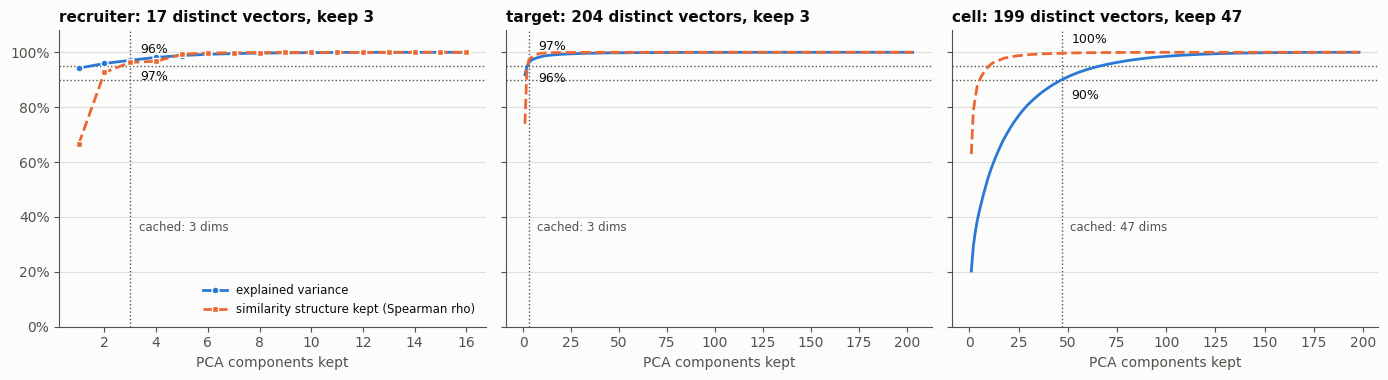

In [8]:
def plot_pca_curves(path):
    """Plot kept variance and kept similarity structure against the number of PCA components, one panel per block."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
    styles = [("variance", SERIES[0], "o", "-", "explained variance"),
              ("similarity_rho", SERIES[1], "s", "--", "similarity structure kept (Spearman rho)")]
    for ax, block in zip(axes, BLOCKS):
        t, k, n = PRESERVATION[block], PCA_DIMS[block], len(FIT[block])
        for target in (VARIANCE_TARGET, SIMILARITY_TARGET):
            if target is not None:
                ax.axhline(target, color=INK_2, lw=1, ls=":", zorder=1)
        ax.axvline(k, color=INK_2, lw=1, ls=":", zorder=1)
        for col, color, marker, ls, label in styles:
            ax.plot(t["dims"], t[col], color=color, marker=marker, ls=ls, lw=2, ms=5 if n < 40 else 0, mec=SURFACE, mew=1.0, label=label, zorder=3)
            y = t.loc[t["dims"] == k, col].item()
            ax.annotate(f"{y:.0%}", (k, y), xytext=(7, -14 if col == "variance" else 7), textcoords="offset points", color=INK, fontsize=9)
        ax.set_title(f"{block}: {n} distinct vectors, keep {k}")
        ax.set_xlabel("PCA components kept")
        ax.set_ylim(0, 1.08)
        ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax.grid(axis="x", visible=False)
        ax.text(k + 0.02 * n, 0.35, f"cached: {k} dims", color=INK_2, fontsize=8.5)
        if block == BLOCKS[0]:
            ax.legend(loc="lower right", fontsize=8.5)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

plot_pca_curves(OUT_DIR / "context_pca_variance.png")

In [9]:
# ----- test: PCA compression ---------------------------------------------------------------------------------------------
# unique_rows on a hand-made table: keeps the first of each repeated row, in order
assert list(unique_rows(np.array([[1., 0], [2, 0], [1, 0], [0, 1], [2, 0]]))) == [0, 1, 3]

# choose_dims on hand-made tables: both targets must hold, the fewest k wins, similarity_target=None ignores the similarity column
T = pd.DataFrame({"dims": [1, 2, 3, 4], "variance": [.60, .90, .98, 1.0], "similarity_rho": [.2, .97, .99, 1.0]})
assert choose_dims(T, .85, .95) == 2 and choose_dims(T, .95, .95) == 3 and choose_dims(T, .85, .99) == 3 and choose_dims(T, .5, None) == 1
T2 = pd.DataFrame({"dims": [1, 2, 3, 4], "variance": [.95, .97, .99, 1.0], "similarity_rho": [.3, .5, .96, 1.0]})
assert choose_dims(T2, .9, None) == 1 and choose_dims(T2, .9, .95) == 3                       # the similarity criterion is what moves k

# similarity_preservation on a planted rank-2 table (plus tiny noise in 6 dims, 12 points): one component keeps 91 % of the variance but only
# part of the similarity structure, two keep everything; the similarity criterion is what moves k from 1 to 2
rng = np.random.default_rng(0)
basis = np.linalg.qr(rng.normal(size=(6, 2)))[0].T
plane = (rng.normal(size=(12, 2)) * [3.0, 1.5]) @ basis + 1e-3 * rng.normal(size=(12, 6))
tp = similarity_preservation(plane)
assert len(tp) == 6 and 0.9 < tp["variance"].iloc[0] < 0.95 and tp["similarity_rho"].iloc[0] < 0.9            # d = 6 < n - 1 caps k at 6
assert tp["variance"].iloc[1] > 0.9999 and tp["similarity_rho"].iloc[1] > 0.999 and abs(tp["similarity_rho"].iloc[-1] - 1) < 1e-9
assert choose_dims(tp, 0.9, None) == 1 and choose_dims(tp, 0.9, 0.95) == 2

for b in BLOCKS:
    X, n, k = FIT[b], len(FIT[b]), PCA_DIMS[b]
    assert 1 <= k <= n - 1 and PCA_MODELS[b].n_components_ == k

    # k reaches both targets and no smaller k does (variance checked against an independent full fit)
    cum = np.cumsum(PCA(svd_solver="full").fit(X).explained_variance_ratio_)
    t = PRESERVATION[b].set_index("dims")
    assert cum[k - 1] >= VARIANCE_TARGET - 1e-9 and PCA_MODELS[b].explained_variance_ratio_.sum() >= VARIANCE_TARGET - 1e-6
    assert SIMILARITY_TARGET is None or t.loc[k, "similarity_rho"] >= SIMILARITY_TARGET - 1e-9
    assert all(cum[j - 1] < VARIANCE_TARGET - 1e-9 or (SIMILARITY_TARGET is not None and t.loc[j, "similarity_rho"] < SIMILARITY_TARGET - 1e-9) for j in range(1, k)), (b, k)
    assert k >= VARIANCE_ONLY_DIMS[b]

    # the fit uses distinct vectors only; every key is projected, duplicates get identical projections
    assert len({row.tobytes() for row in FIT[b].astype(np.float32)}) == n
    Z = np.stack(list(REDUCED[b].values()))
    assert list(REDUCED[b]) == VOCAB[b] and Z.shape == (len(VOCAB[b]), k) and Z.dtype == np.float32 and np.isfinite(Z).all()
    by_vec = {}
    for key, row in zip(VOCAB[b], MATRIX[b]):
        by_vec.setdefault(row.tobytes(), []).append(key)
    for keys in by_vec.values():
        assert all(np.array_equal(REDUCED[b][keys[0]], REDUCED[b][other]) for other in keys[1:])

    # centred on the distinct vectors, orthonormal components, and an orthogonal projection never stretches distances
    Zfit = PCA_MODELS[b].transform(FIT[b])
    assert np.abs(Zfit.mean(axis=0)).max() < 1e-6 * max(1.0, np.abs(Zfit).max())
    comps = PCA_MODELS[b].components_
    assert np.allclose(comps @ comps.T, np.eye(k), atol=1e-8)
    assert np.all(pdist(Zfit) <= pdist(FIT[b]) + 1e-6)
    assert np.all(np.diff(Zfit.var(axis=0)) <= 1e-9 * max(1.0, Zfit.var(axis=0).max()))   # ordered by variance

    # preservation table: ends at the lossless n - 1 (variance 1, same similarity structure), variance never decreases
    t = PRESERVATION[b]
    assert list(t.columns) == ["dims", "variance", "similarity_rho"] and t["dims"].iloc[-1] == n - 1
    assert abs(t["variance"].iloc[-1] - 1) < 1e-8 and abs(t["similarity_rho"].iloc[-1] - 1) < 1e-6 and np.all(np.diff(t["variance"]) >= -1e-12)
assert (OUT_DIR / "context_pca_variance.png").stat().st_size > 10_000
print("PCA: OK (" + "; ".join(f"{b}: {PCA_DIMS[b]} of {len(FIT[b]) - 1} possible dims keep {PCA_MODELS[b].explained_variance_ratio_.sum():.1%}, "
                              f"similarity rho {PRESERVATION[b].set_index('dims').loc[PCA_DIMS[b], 'similarity_rho']:.3f}" for b in BLOCKS) + ")")

PCA: OK (recruiter: 3 of 16 possible dims keep 97.1%, similarity rho 0.963; target: 3 of 203 possible dims keep 96.2%, similarity rho 0.972; cell: 47 of 198 possible dims keep 90.0%, similarity rho 0.997)


## 4. Cache

Written to `TACKAI_CACHE` (`~/.cache/tackai` unless set in `.env`) in the `.npz` layout (`{key: vector}`) that `EmbeddingMixin.save` / `.load` use, so every full file also loads with the repo's own
`ProteinEmbedding(load_from_cache=True, filename=...)` / `CellEmbedding(load_from_cache=True, filename=...)`. Three files per block, plus one metadata file for all:

| file | content |
|---|---|
| `protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block={recruiter,target}.npz` | full 640-d embedding per sequence (sum over residues and windows) |
| `cell_embeddings_model=sentence-transformer_pooling=mean.npz` | full 768-d embedding per accession (mean over tokens); the old `pooling=sum` file is left alone |
| `<full name without .npz>_pca{k}.npz` | the same keys, compressed to the `k` components of that block |
| `<full name without .npz>_pca{k}_model.npz` | the fitted PCA (`mean_`, `components_`, `explained_variance_ratio_`), to project a vector that is not in the table |
| `context_embeddings_meta.json` | settings, vocabulary sizes, `k` and kept variance per block, and the file names (the standalone cell at the end reads its paths from here) |

The window size is in the protein file names because it changes the vectors of long sequences; `k` is in the PCA file names, so a vocabulary that grows and needs another `k` writes new files instead of overwriting old ones.

In [10]:
class StoredEmbedding(EmbeddingMixin):
    """Store for precomputed vectors; saves and loads like the other TACK embeddings.

    The vectors are computed in this notebook, so a key that is not in the table raises a ``KeyError``.
    """

    def _transform_batch(self, keys):
        raise KeyError(f"no cached embedding for {keys[:3]}")

def cache_files(block):
    """Cache file names of a block: full embeddings, PCA embeddings and the fitted PCA."""
    stem, k = stem_of(block), PCA_DIMS[block]
    return {"full": f"{stem}.npz", "pca": f"{stem}_pca{k}.npz", "pca_model": f"{stem}_pca{k}_model.npz"}

CACHE_FILES = {b: cache_files(b) for b in BLOCKS}
META_FILE = "context_embeddings_meta.json"
assert all(CACHE_FILES[b]["full"] == FULL_FILES[b] for b in BLOCKS)

# full embeddings, written by the classes that computed them
for b in ("recruiter", "target"):
    ProteinEmbedding(embeddings_type="esm", pretrained_model=ESM_MODEL, pooling=PROTEIN_POOLING, embeddings=dict(TABLES[b]),
                     filename=CACHE_FILES[b]["full"], cache_dir=CACHE_DIR).save()
cell_encoder.embeddings = dict(TABLES["cell"])
cell_encoder.save(filename=CACHE_FILES["cell"]["full"], cache_dir=CACHE_DIR)

# PCA embeddings and the fitted PCA
for b in BLOCKS:
    files, pca = CACHE_FILES[b], PCA_MODELS[b]
    StoredEmbedding(embeddings=REDUCED[b], filename=files["pca"], cache_dir=CACHE_DIR).save()
    np.savez(CACHE_DIR / files["pca_model"], mean_=pca.mean_.astype(np.float32), components_=pca.components_.astype(np.float32),
             explained_variance_ratio_=pca.explained_variance_ratio_.astype(np.float32))

META = {"notebook": "notebooks/context_embeddings.ipynb", "not_found_description": NOT_FOUND, "variance_target": VARIANCE_TARGET,
        "protein": {"model": ESM_MODEL, "pooling": PROTEIN_POOLING, "window": WINDOW, "window_pooling": "sum of the window vectors", "batch_size": 1},
        "cell": {"model": CELL_MODEL, "pooling": CELL_POOLING, "key": "Cellosaurus accession"},
        "source": {"csv_dir": "data/yaochen", "files": sorted(ROWS["file"].unique().tolist()), "test_file_included": TEST_FILE in set(ROWS["file"])},
        "blocks": {b: {"n_keys": len(VOCAB[b]), "n_distinct_vectors": int(len(FIT[b])), "embedding_dim": int(EMB_DIM[b]), "pca_dims": int(PCA_DIMS[b]),
                       "explained_variance": float(PCA_MODELS[b].explained_variance_ratio_.sum()), "files": CACHE_FILES[b]} for b in BLOCKS}}
(CACHE_DIR / META_FILE).write_text(json.dumps(META, indent=1))

for name in [META_FILE] + [f for b in BLOCKS for f in CACHE_FILES[b].values()]:
    print(f"{(CACHE_DIR / name).stat().st_size / 1024:9.1f} KB  {name}")

      2.2 KB  context_embeddings_meta.json
     66.1 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block=recruiter.npz
     23.8 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block=recruiter_pca3.npz
     10.8 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block=recruiter_pca3_model.npz
    855.9 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block=target.npz
    348.2 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block=target_pca3.npz
     10.8 KB  protein_embeddings_esm_model=facebook-esm2_t30_150M_UR50D_pooling=sum_window=1022_block=target_pca3_model.npz
    652.1 KB  cell_embeddings_model=sentence-transformer_pooling=mean.npz
     86.0 KB  cell_embeddings_model=sentence-transformer_pooling=mean_pca47.npz
    145.0 KB  cell_embeddings_model=sentence-transformer_pooling=mean_pca47_model.np

In [11]:
# ----- test: cache files -------------------------------------------------------------------------------------------------
for b in BLOCKS:
    files, k = CACHE_FILES[b], PCA_DIMS[b]
    assert all((CACHE_DIR / f).is_file() and (CACHE_DIR / f).stat().st_size > 0 for f in files.values()), files
    assert files["pca"].endswith(f"_pca{k}.npz") and files["pca_model"].endswith(f"_pca{k}_model.npz")

    # full embeddings: round trip through the repo's own class for that block, same keys in the same order, bit-identical vectors
    if b == "cell":
        full = CellEmbedding(embeddings_type="sentence_transformer", pretrained_model=CELL_MODEL, pooling=CELL_POOLING, not_found_description=NOT_FOUND,
                             load_from_cache=True, filename=files["full"], cache_dir=CACHE_DIR)
    else:
        full = ProteinEmbedding(embeddings_type="esm", pretrained_model=ESM_MODEL, pooling=PROTEIN_POOLING, load_from_cache=True,
                                filename=files["full"], cache_dir=CACHE_DIR)
    assert list(full.embeddings) == VOCAB[b], b
    assert all(np.array_equal(full.embeddings[key], TABLES[b][key]) for key in VOCAB[b])
    assert full.shape() == (EMB_DIM[b],)

    reduced = StoredEmbedding(load_from_cache=True, filename=files["pca"], cache_dir=CACHE_DIR)
    assert list(reduced.embeddings) == VOCAB[b] and reduced.shape() == (k,)
    assert all(np.array_equal(reduced[key], REDUCED[b][key]) for key in VOCAB[b])

    # the saved PCA reproduces the cached compression from the saved full vectors alone
    side = np.load(CACHE_DIR / files["pca_model"])
    assert set(side.files) == {"mean_", "components_", "explained_variance_ratio_"}
    assert side["mean_"].shape == (EMB_DIM[b],) and side["components_"].shape == (k, EMB_DIM[b]) and side["explained_variance_ratio_"].shape == (k,)
    assert side["explained_variance_ratio_"].sum() >= VARIANCE_TARGET - 1e-4
    projected = (np.stack(list(full.embeddings.values())).astype(np.float64) - side["mean_"]) @ side["components_"].T
    Z = np.stack(list(reduced.embeddings.values()))
    assert np.allclose(projected, Z, rtol=1e-3, atol=1e-3 * np.abs(Z).max()), (b, np.abs(projected - Z).max())

# a key that is not cached raises instead of silently inventing a vector
try:
    reduced.transform(["not a cached key"])
    raise AssertionError("an uncached key was accepted")
except KeyError:
    pass

# the old cell cache is untouched and the new files do not collide with it or with each other
assert len({f for b in BLOCKS for f in CACHE_FILES[b].values()}) == 3 * len(BLOCKS)
assert "pooling=sum.npz" not in CACHE_FILES["cell"]["full"] and "pooling=mean" in CACHE_FILES["cell"]["full"]

meta = json.loads((CACHE_DIR / META_FILE).read_text())
assert meta["blocks"].keys() == set(BLOCKS) and all(meta["blocks"][b]["files"] == CACHE_FILES[b] for b in BLOCKS)
assert all(meta["blocks"][b]["pca_dims"] == PCA_DIMS[b] and meta["blocks"][b]["n_keys"] == len(VOCAB[b]) for b in BLOCKS)
assert meta["protein"]["pooling"] == "sum" and meta["cell"]["pooling"] == "mean" and meta["source"]["test_file_included"] is True
print(f"cache: OK ({3 * len(BLOCKS) + 1} files in {CACHE_DIR}; full files reload through ProteinEmbedding / CellEmbedding)")

cache: OK (10 files in /Users/ribes/.cache/tackai; full files reload through ProteinEmbedding / CellEmbedding)


## 5. Similarity of the entities

Cosine similarity between the **PCA-compressed** vectors, i.e. the representation a model would be given. (Raw sum-pooled vectors all share a large common component, so their cosines are close to 1 for every pair and
hide the differences; PCA centring removes it. The printout below gives both.) Rows and columns are ordered by hierarchical clustering (average linkage on 1 - similarity, optimal leaf order), so alike entities sit next to
each other. The colour scale starts at the lowest off-diagonal similarity, rounded down. Recruiters are shown in full; targets and cell lines are the 25 most frequent entities (a 200 x 200 annotated matrix is unreadable);
`n` is the number of CSV rows (the files overlap, so these are not unique measurements).

recruiter: mean off-diagonal cosine 0.942 on the raw vectors, +0.187 after PCA
target: mean off-diagonal cosine 0.924 on the raw vectors, +0.104 after PCA
cell: mean off-diagonal cosine 0.586 on the raw vectors, +0.010 after PCA


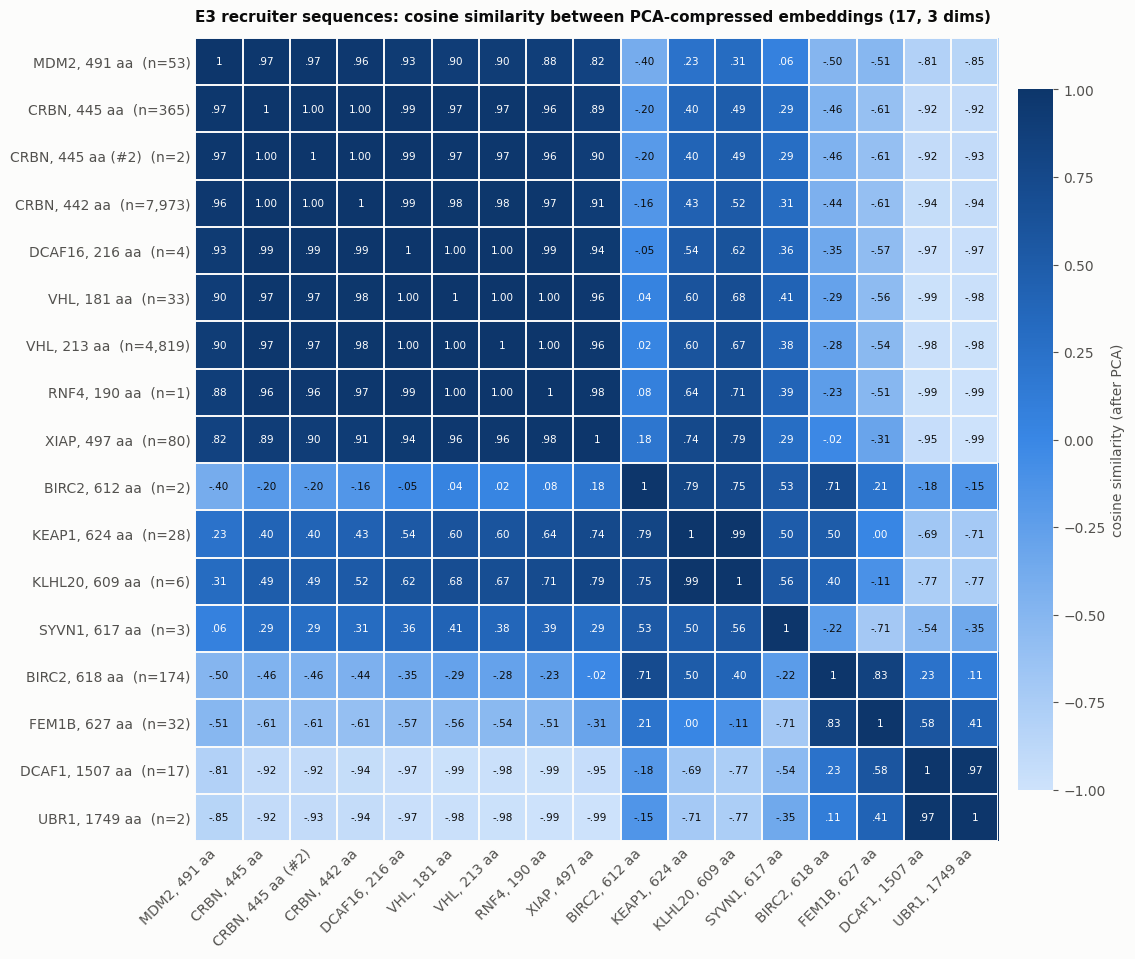

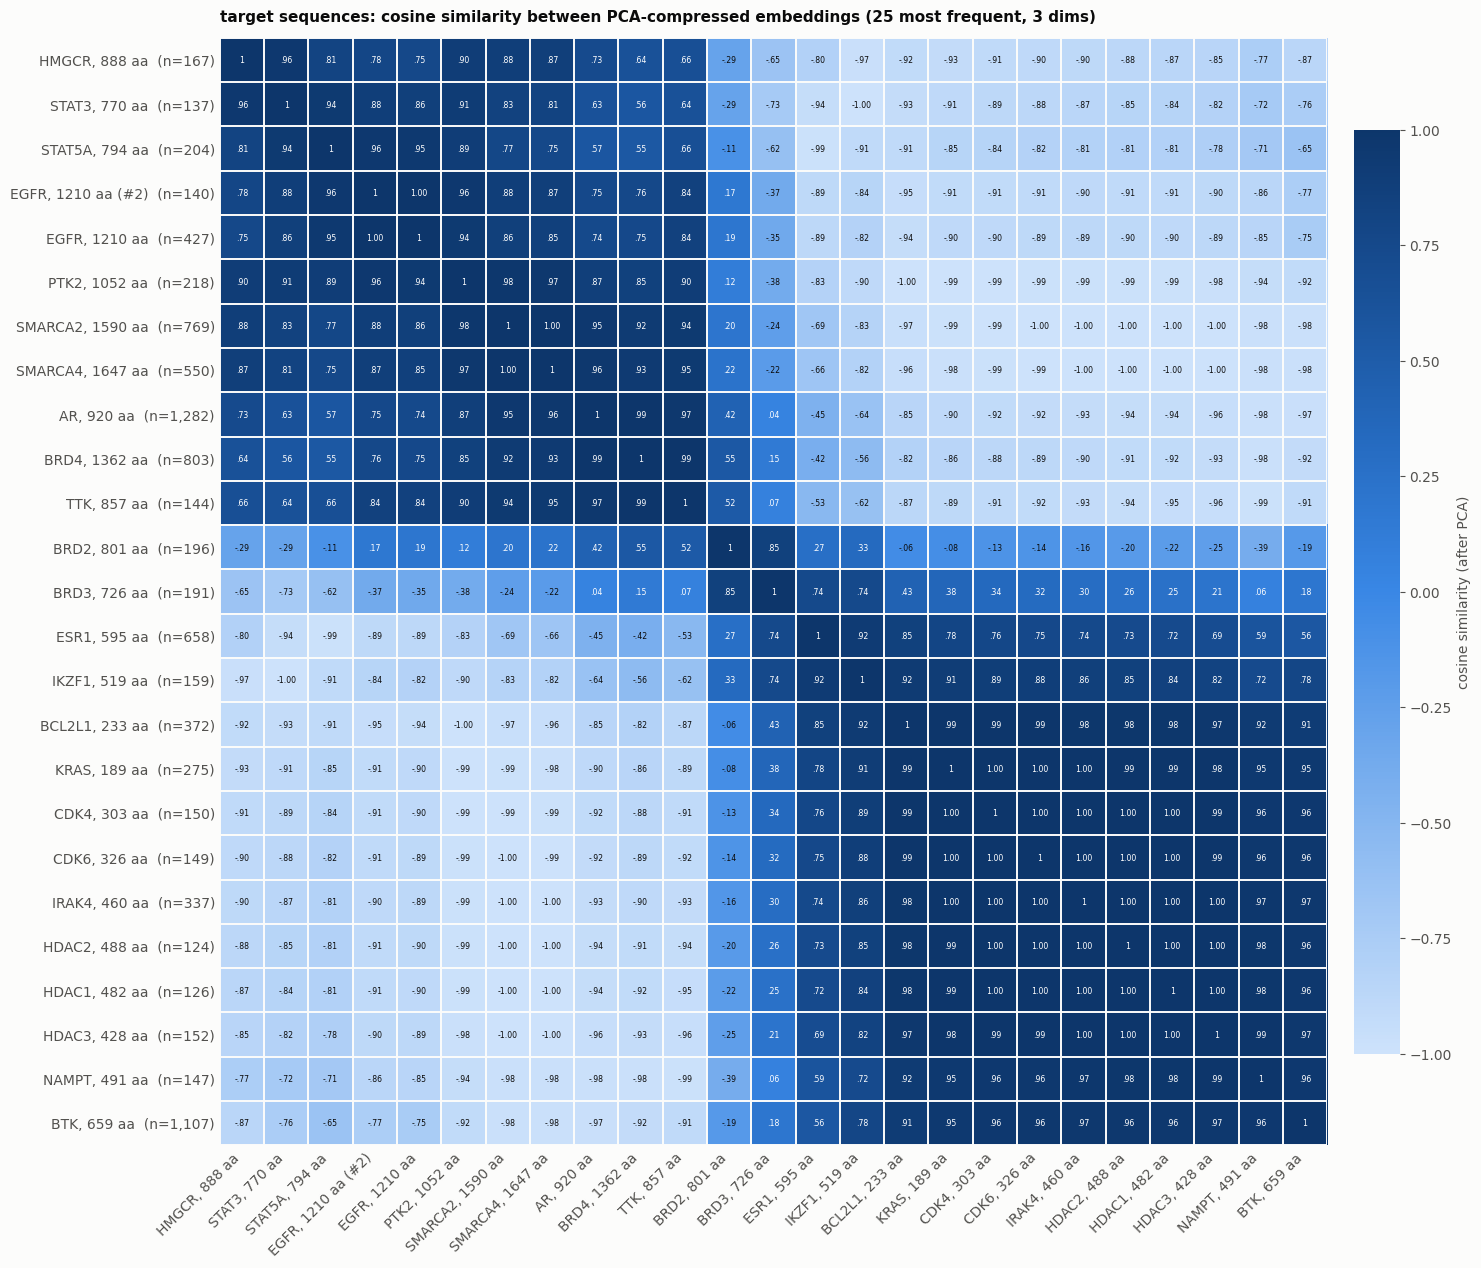

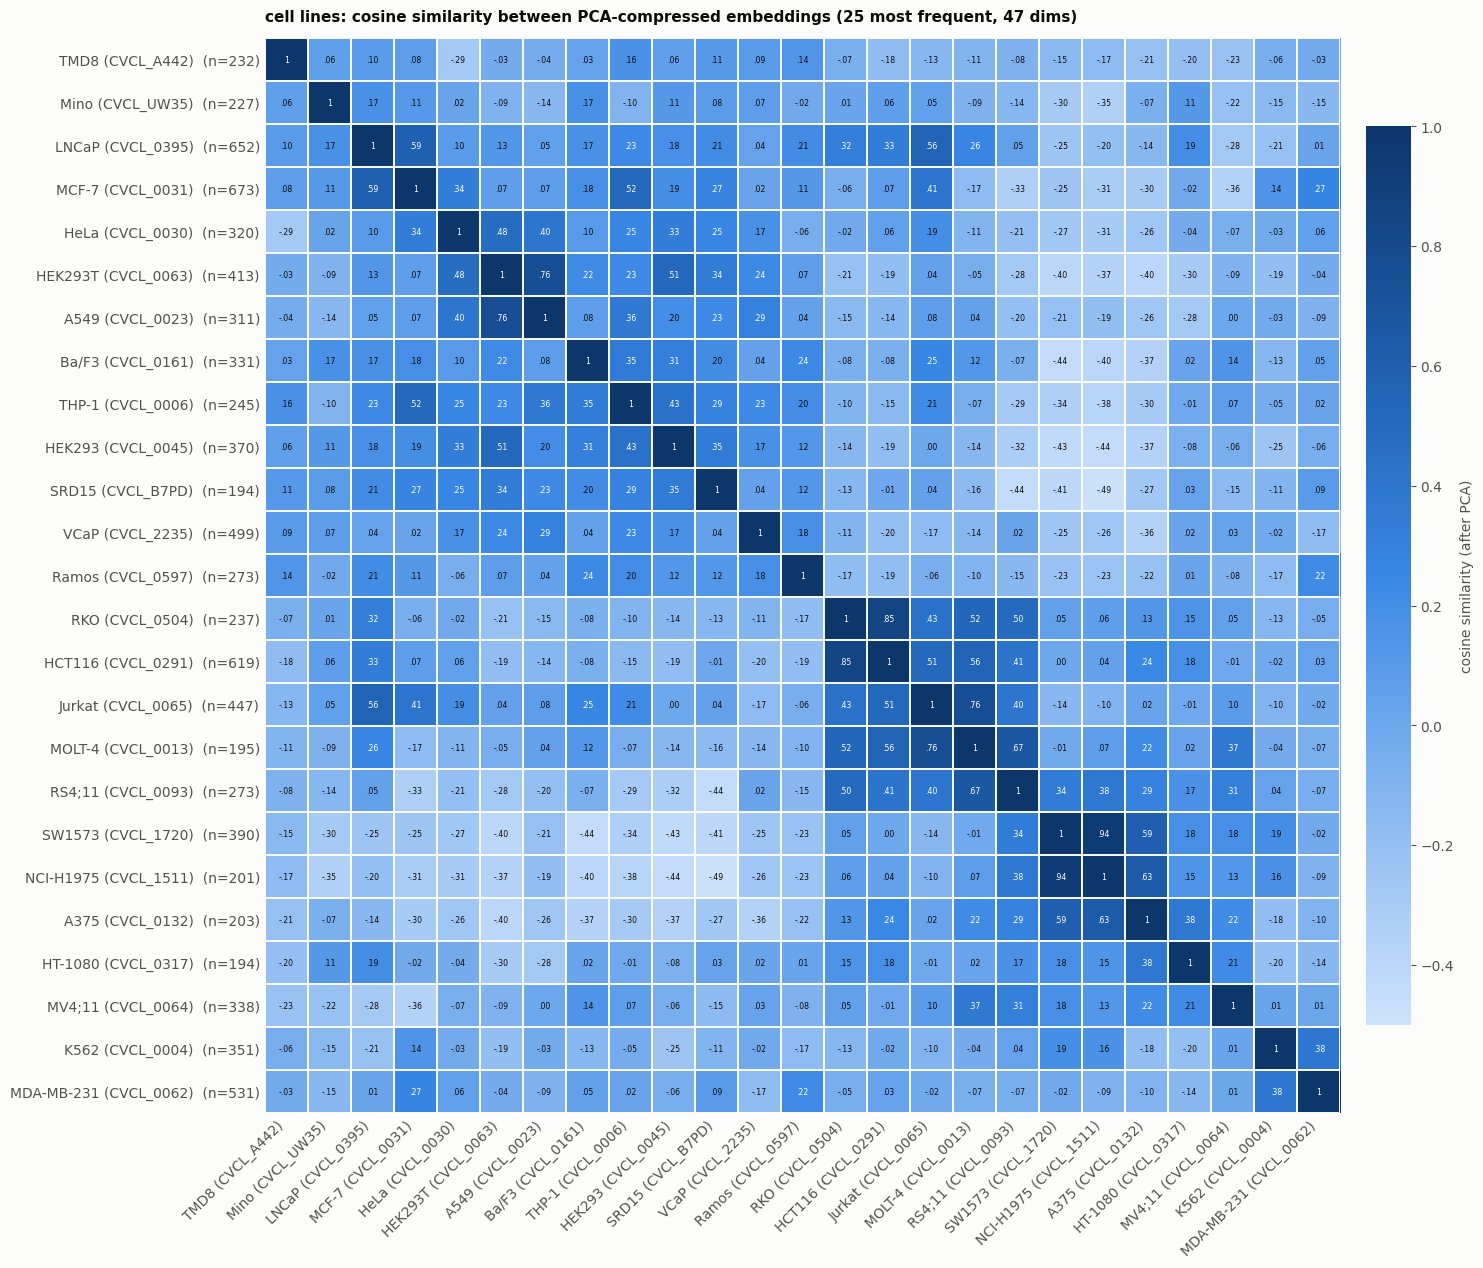

In [12]:
Z_ALL = {b: np.stack([REDUCED[b][k] for k in VOCAB[b]]).astype(np.float64) for b in BLOCKS}
SIMILARITY = {b: cosine_matrix(Z_ALL[b]) for b in BLOCKS}
RAW_SIMILARITY = {b: cosine_matrix(MATRIX[b].astype(np.float64)) for b in BLOCKS}
TOP_N = {"recruiter": None, "target": 25, "cell": 25}
for b in BLOCKS:
    off = ~np.eye(len(VOCAB[b]), dtype=bool)
    print(f"{b}: mean off-diagonal cosine {RAW_SIMILARITY[b][off].mean():.3f} on the raw vectors, {SIMILARITY[b][off].mean():+.3f} after PCA")

def cluster_order(sim):
    """Row order that puts similar entities next to each other (average linkage, optimal leaf order).

    Args:
        sim: Symmetric similarity matrix, shape (n, n), diagonal 1.

    Returns:
        List with a permutation of ``range(n)``.
    """
    dist = np.clip(1 - sim, 0, None)
    dist = (dist + dist.T) / 2
    np.fill_diagonal(dist, 0)
    condensed = squareform(dist, checks=False)
    return list(leaves_list(optimal_leaf_ordering(linkage(condensed, method="average"), condensed)))

def plot_similarity(block, path):
    """Clustered heatmap of the cosine similarity between the PCA-compressed vectors of one block's (most frequent) entities."""
    keys = VOCAB[block] if TOP_N[block] is None else VOCAB[block][:TOP_N[block]]
    idx = [VOCAB[block].index(k) for k in keys]
    sim = SIMILARITY[block][np.ix_(idx, idx)]
    K = len(keys)
    order = cluster_order(sim)
    S = sim[np.ix_(order, order)]
    vmin = np.floor(sim[~np.eye(K, dtype=bool)].min() * 10) / 10
    short = lambda key: textwrap.shorten(LABELS[block][key], width=34, placeholder="...")
    ordered = [keys[i] for i in order]

    side = 0.42 * K + 3.4
    fig, ax = plt.subplots(figsize=(side + 1.2, side * 0.92))
    im = ax.imshow(S, cmap=SEQ_CMAP, vmin=vmin, vmax=1.0)
    ax.set_xticks(range(K), [short(k) for k in ordered], rotation=45, ha="right")
    ax.set_yticks(range(K), [f"{short(k)}  (n={COUNTS[block].get(k, 0):,})" for k in ordered])
    ax.set_xticks(np.arange(-0.5, K, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, K, 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=1.4)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fontsize = 7.5 if K <= 18 else 5.6
    for r in range(K):
        for c in range(K):
            v = S[r, c]
            r_, g_, b_, _ = SEQ_CMAP((v - vmin) / (1 - vmin))
            dark_cell = 0.299 * r_ + 0.587 * g_ + 0.114 * b_ < 0.5
            ax.text(c, r, "1" if r == c else f"{v:.2f}".replace("0.", ".", 1), ha="center", va="center", fontsize=fontsize,
                    color="#ffffff" if dark_cell else INK)
    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("cosine similarity (after PCA)")
    cbar.outline.set_visible(False)
    what = {"recruiter": "E3 recruiter sequences", "target": "target sequences", "cell": "cell lines"}[block]
    ax.set_title(f"{what}: cosine similarity between PCA-compressed embeddings ({K}{' most frequent' if TOP_N[block] else ''}, {PCA_DIMS[block]} dims)", loc="left", pad=12)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

for b in BLOCKS:
    plot_similarity(b, OUT_DIR / f"context_similarity_{b}.png")

In [13]:
# ----- test: similarity matrices -----------------------------------------------------------------------------------------
# cluster_order on a planted example: (0, 1) and (2, 3) are the close pairs, so each pair must end up adjacent
S4 = np.array([[1, .9, .1, .2], [.9, 1, .15, .1], [.1, .15, 1, .8], [.2, .1, .8, 1]])
order4 = list(cluster_order(S4))
pos = {i: p for p, i in enumerate(order4)}
assert sorted(order4) == [0, 1, 2, 3] and abs(pos[0] - pos[1]) == 1 and abs(pos[2] - pos[3]) == 1, order4

# cosine_matrix on hand-made vectors: parallel -> 1, orthogonal -> 0, opposite -> -1, scale-invariant
v = np.array([[1, 0], [0, 1], [-1, 0], [2, 0]], dtype=float)
assert np.allclose(cosine_matrix(v), [[1, 0, -1, 1], [0, 1, 0, 0], [-1, 0, 1, -1], [1, 0, -1, 1]])

for b in BLOCKS:
    S, K = SIMILARITY[b], len(VOCAB[b])
    assert S.shape == (K, K) and np.allclose(S, S.T, atol=1e-8) and np.allclose(np.diag(S), 1, atol=1e-8) and S.min() >= -1 - 1e-9
    assert sorted(cluster_order(S)) == list(range(K))
    assert (OUT_DIR / f"context_similarity_{b}.png").stat().st_size > 10_000

# similarity must reflect sequence identity: entities of the same gene (isoforms, orthologues, point mutants) are closer to each other than to other genes.
# Fixed before looking at the matrices: it is the one structural fact the sequence data already contain.
for b in ("recruiter", "target"):
    sub = ROWS.dropna(subset=[b, f"{b}_label"])
    gene = sub.groupby(b)[f"{b}_label"].agg(lambda s: s.value_counts().index[0]).str.upper().reindex(VOCAB[b]).fillna("?").to_numpy()
    same = (gene[:, None] == gene[None, :]) & (gene[:, None] != "?")
    eye, S = np.eye(len(gene), dtype=bool), SIMILARITY[b]
    siblings = (same & ~eye).any(axis=1)
    nearest = np.where(eye, -np.inf, S).argmax(axis=1)
    nn_same = same[np.arange(len(gene)), nearest][siblings].mean()
    within, between = S[same & ~eye].mean(), S[~same].mean()
    assert siblings.sum() >= 2 and within > between, (b, within, between)
    assert nn_same >= 0.5, (b, nn_same)
    print(f"  {b}: mean cosine {within:+.2f} within a gene vs {between:+.2f} between genes; nearest neighbour is the same gene for {nn_same:.0%} of the {siblings.sum()} sequences that have one")
print("similarity matrices: OK (figures in " + OUT_DIR.name + "/)")

  recruiter: mean cosine +0.94 within a gene vs +0.16 between genes; nearest neighbour is the same gene for 71% of the 7 sequences that have one
  target: mean cosine +1.00 within a gene vs +0.10 between genes; nearest neighbour is the same gene for 88% of the 52 sequences that have one
similarity matrices: OK (figures in context_embedding_results/)


## 6. Summary and how to use the cache

**Reading the result** (executed values):

* **Sizes.** 17 recruiter sequences, 204 target sequences and 201 cell-line keys (200 Cellosaurus accessions plus the not-found description) from 7 CSVs; `PROTAC-test.csv` is included and adds none of them.
  They are cached as **3, 3 and 47 PCA components**.
* **Why 3 for the proteins.** With sum pooling the first principal component is sequence length (Spearman 0.85 for recruiters, 0.97 for targets). It alone explains 94 % / 92 % of the variance, so the 90 % variance rule would have cached a single
  component that keeps only 0.66 / 0.74 of the similarity structure. Requiring the similarity structure too (rho >= 0.95) gives 3 components: 97.1 % / 96.2 % of the variance, rho 0.963 / 0.972.
* **Why 47 for the cell lines.** Sentence embeddings of text spread their variance over many directions (16 components keep 66 %), so the 90 % variance rule is the binding one; the similarity structure is already at rho 0.973 with 16 components.
  If a smaller cell block is wanted, lower `VARIANCE_TARGET` for it.
* **The compressed space respects identity.** Sequences of the same gene (isoforms, orthologues, point mutants) have a mean cosine of 0.94 (recruiters) and 1.00 (targets), against 0.16 and 0.10 between different genes; the nearest neighbour is the same gene for
  71 % of the 7 recruiters and 88 % of the 52 targets that have a same-gene sibling (asserted in the test cell). CDK4 / CDK6 and HDAC1 / 2 / 3 sit at about 1.00 in the target matrix. Cell lines from the same tissue pair up
  (SW1573 / NCI-H1975 0.94 lung, HCT116 / RKO 0.85 colon, Jurkat / MOLT-4 0.76 T-cell leukaemia).
* **Caveat: length leaks into the protein blocks.** Sum pooling makes the vector norm grow with sequence length, and the first of the 3 components still tracks it. In the recruiter matrix, short, unrelated proteins (VHL, CRBN, DCAF16, MDM2, RNF4, XIAP) are all close
  (VHL / CRBN 0.97 to 0.98) while two BIRC2 forms of 612 and 618 residues are only 0.71 apart. Treat these features as partly a length feature. If that is not wanted, `ProteinEmbedding(pooling="mean")` is a one-argument change
  (the file names carry the pooling, so the sum files are not overwritten).

Things to decide when this goes into a model:

* the compressed vectors are PCA-centred over the vocabulary tables; scale them like any other feature block;
* each PCA is fitted on its vocabulary table only (no labels, no data rows), so it cannot leak across CV folds;
* a sequence or accession that is not in the tables needs an embedding first: encode it with `ProteinEmbedding` / `CellEmbedding` (windowing long sequences as in section 2), then `project` it with the cached PCA.

The last cell is **standalone**: it has its own imports, reads its file names from `context_embeddings_meta.json`, and needs nothing from the cells above.

In [14]:
# ===== Standalone cell: everything needed to use the cached context embeddings. Run it in a fresh kernel; no earlier cell is required. =====
import json
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv, find_dotenv

from tackai.data.utils import get_cache_dir

load_dotenv(find_dotenv())                          # TACKAI_CACHE from .env when present, otherwise ~/.cache/tackai
CACHE_DIR = Path(get_cache_dir())
META = json.loads((CACHE_DIR / "context_embeddings_meta.json").read_text())   # file names, dimensions and settings of the cache
NOT_FOUND = META["not_found_description"]           # key of the cell-line vector used for a missing / unknown cell line
_TABLES = {}

def load_table(block, reduced=False):
    """Cached embeddings of a block as ``{key: vector}``.

    Args:
        block: ``"recruiter"`` or ``"target"`` (keys are amino-acid sequences), or ``"cell"`` (keys are Cellosaurus accessions, plus ``NOT_FOUND``).
        reduced: ``True`` for the PCA-compressed vectors (``META["blocks"][block]["pca_dims"]`` dims), ``False`` for the full ones.
    """
    if (block, reduced) not in _TABLES:
        _TABLES[(block, reduced)] = dict(np.load(CACHE_DIR / META["blocks"][block]["files"]["pca" if reduced else "full"]))
    return _TABLES[(block, reduced)]

def embed(block, keys, reduced=False):
    """Look up the cached vector of every key, in order, as a float32 array of shape (len(keys), dim).

    Sequences are looked up by their stripped string and raise ``KeyError`` when unknown. Cell lines that are missing (None / NaN / "")
    get the ``NOT_FOUND`` vector; an accession that is not in the cache raises ``KeyError`` instead of being silently replaced.
    """
    table = load_table(block, reduced)
    out = []
    for key in keys:
        missing = key is None or (not isinstance(key, str) and pd.isna(key)) or (isinstance(key, str) and not key.strip())
        if block == "cell" and missing:
            out.append(table[NOT_FOUND])
        elif missing:
            raise KeyError(f"missing {block} key")
        else:
            out.append(table[str(key).strip()])
    return np.stack(out) if out else np.empty((0, META["blocks"][block]["pca_dims" if reduced else "embedding_dim"]), dtype=np.float32)

def project(block, X):
    """Project full-dimension vectors of a block (rows of ``X``, e.g. from ProteinEmbedding / CellEmbedding) with the cached PCA."""
    side = np.load(CACHE_DIR / META["blocks"][block]["files"]["pca_model"])
    return (np.asarray(X, dtype=np.float64) - side["mean_"]) @ side["components_"].T

# ----- example: feature matrices for the first rows of TACKv2 -----------------------------------------------------------------
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "yaochen").is_dir())
rows = pd.read_csv(root / "data" / "yaochen" / "TACKv2.csv", usecols=["Recruiter_Sequence", "Degradation_Target_Sequence", "Cell_Line_ID"],
                   dtype="string", nrows=1000).dropna(subset=["Recruiter_Sequence", "Degradation_Target_Sequence"])
X_recruiter = embed("recruiter", rows["Recruiter_Sequence"], reduced=True)
X_target = embed("target", rows["Degradation_Target_Sequence"], reduced=True)
X_cell = embed("cell", rows["Cell_Line_ID"], reduced=True)                      # missing accession -> the NOT_FOUND vector
for name, X in [("recruiter", X_recruiter), ("target", X_target), ("cell", X_cell)]:
    assert X.shape == (len(rows), META["blocks"][name]["pca_dims"]) and np.isfinite(X).all()
    print(f"{name:9s} {X.shape}  (full embedding: {META['blocks'][name]['embedding_dim']} dims, PCA keeps {META['blocks'][name]['explained_variance']:.1%} of the variance)")

# the cached PCA reproduces the cached compressed vectors from the cached full vectors
first = rows["Degradation_Target_Sequence"].iloc[0]
assert np.allclose(project("target", load_table("target")[first][None]), load_table("target", reduced=True)[first], rtol=1e-3, atol=1e-3 * np.abs(X_target).max())

recruiter (950, 3)  (full embedding: 640 dims, PCA keeps 97.1% of the variance)
target    (950, 3)  (full embedding: 640 dims, PCA keeps 96.2% of the variance)
cell      (950, 47)  (full embedding: 768 dims, PCA keeps 90.0% of the variance)
